# Урок 9 — Собираем картинку обучением гауссиан

[План курса](../../README_ru.md) · [Предыдущий урок](lesson-08.ipynb) · [English](../en/lesson-09.ipynb)

В редакторе пятен мы двигали каждое число сами. Потом научили один колокол находить свой центр. Теперь вместо одного колокола будет набор цветных пятен, а вместо кривой — небольшая картинка. Цикл останется тем же: нарисовать, сравнить, получить градиенты, изменить параметры.

Начнём с цветных геометрических фигур. У них есть ровные края и тонкая полоска: сразу видно, где мягким пятнам хватает свободы, а где картинка пока расплывается. Здесь нет скрытой фотографии, уже разложенной на готовые гауссианы. Образец — обычный массив RGB, к которому модель постепенно приближается.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import math
import numpy as np
import torch
from IPython.display import display

course_root = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
                   if (folder / "training_math.py").is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from training_math import (chain_example, autograd_check, fit_one_gaussian,
                           make_target, initialize, render_torch, projected_step,
                           fit_image, parameters_scene, load_image, small_cpu_work)
from training_demos import (chain_figure, learning_figure, autograd_lab,
                            demo_fit, fitting_figure, detail_figure, fitting_lab)
LANG = 'ru'

## 1. До, после и всё, что между ними

В основном примере $64$ пятна, картинка $32\times32$ пикселя, начальная ширина $0.55$ и размер шага $\eta=4$. Центры разложены по сетке. Начальные цвета взяты из образца рядом с каждым центром, с небольшой примесью белого. Это уже полезная подсказка, поэтому первая картинка не является случайным шумом.

После $120$ обновлений MSE уменьшается примерно с $0.032308$ до $0.012089$. Цветные области становятся узнаваемее, но ошибка не исчезает. По карте различий видно, что заметная её часть остаётся на границах. Количество пятен, их начальная ширина и место старта меняют этот результат.

Поле «Образец» переключает фигуры, цветок и мелкие клетки. У клеток особенно хорошо виден предел грубого представления. Смена параметров задаёт новый опыт; «Обучение» строит для него новую последовательность. Сцена в JSON внизу содержит уже обученные пятна.

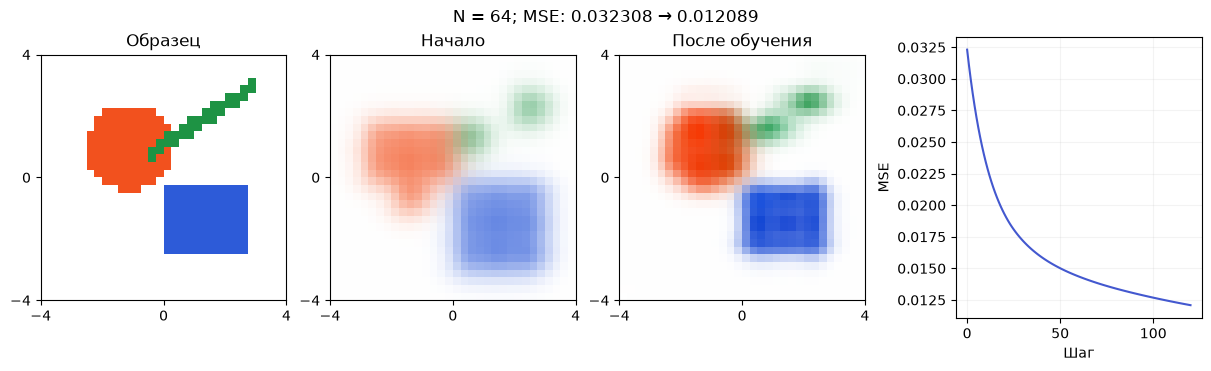

In [2]:
display(fitting_figure(language=LANG))
display(fitting_lab(language=LANG))

## 2. Какие именно числа обучаются

Оставим знакомую сцену из урока 5: координаты от $-4$ до $4$, ось $x$ направлена вправо, $y$ вверх, белый фон. Список пятен идёт от переднего к заднему. Этот порядок фиксирован на всём протяжении обучения.

У каждого пятна восемь изменяемых чисел:

| Параметр | Сколько чисел | Смысл и границы в этом опыте |
|---|---:|---|
| $\mu_x,\mu_y$ | 2 | Центр в координатах сцены, от $-4$ до $4$ |
| $\sigma_x,\sigma_y$ | 2 | Ширины в тех же единицах, от $0.2$ до $3$ |
| $c_R,c_G,c_B$ | 3 | Числовые каналы RGB, от $0$ до $1$ |
| $o$ | 1 | Непрозрачность в центре, от $0$ до $1$ |

Угол остаётся нулевым. Пятна могут вытягиваться по горизонтали и вертикали, но пока не поворачиваются. Ни число пятен, ни порядок слоёв этот алгоритм тоже не меняет. Для $64$ пятен получается $64\cdot8=512$ обучаемых чисел. Фон не обучается.

Мы специально оставили эту модель небольшой. Она уже способна восстановить изображение и позволяет проследить весь путь ошибки. Добавление вращения расширит набор форм, но потребует ещё одного параметра и его градиента.

## 3. Из параметров обратно в пиксель

Для пятна с номером $i$ и пикселя в точке $(x,y)$ используется прежний вес:

$$
G_i(x,y)=\exp\left[-\frac12\left(
\left(\frac{x-\mu_{x,i}}{\sigma_{x,i}}\right)^2+
\left(\frac{y-\mu_{y,i}}{\sigma_{y,i}}\right)^2\right)\right].
$$

Индекс $i$ только выбирает пятно из списка. Сначала вычитаем его центр, затем делим каждое смещение на соответствующую ширину, возводим оба результата в квадрат и складываем. Полученную сумму делим на $-2$ и берём экспоненту. Это формула из урока 3, теперь повторённая для каждого пятна.

Например, у пикселя $(1,0)$ и пятна с центром $(0,0)$, ширинами $(1,2)$ относительные смещения равны $1/1=1$ и $0/2=0$. Сумма квадратов $1+0=1$, показатель $-0.5$, вес $0.606530660$. При непрозрачности $o=0.5$ локальная непрозрачность равна

$$
\alpha_i=o_iG_i=0.5\cdot0.606530660=0.303265330.
$$

Дальше работает смешивание из урока 5. $T_i$ — доля света, ещё не перекрытая передними пятнами перед слоем $i$. Перед первым слоем $T_1=1$. Каждый слой отдаёт в пиксель $T_i\alpha_i\mathbf c_i$ и оставляет следующему $T_{i+1}=T_i(1-\alpha_i)$. Жирная буква $\mathbf c_i$ означает три цветовых числа; одно и то же число $T_i\alpha_i$ умножается на каждое из них.

При трёх локальных непрозрачностях $0.5,0.25,0.2$:

| Перед слоем | $T_i$ | Его вес $T_i\alpha_i$ | Осталось после него |
|---|---:|---:|---:|
| 1 | $1$ | $1\cdot0.5=0.5$ | $1\cdot0.5=0.5$ |
| 2 | $0.5$ | $0.5\cdot0.25=0.125$ | $0.5\cdot0.75=0.375$ |
| 3 | $0.375$ | $0.375\cdot0.2=0.075$ | $0.375\cdot0.8=0.3$ |

Фон получает последние $0.3$. Сумма весов $0.5+0.125+0.075+0.3=1$. При цветах «красный, синий, зелёный» и белом фоне итог — $(0.8,0.375,0.425)$: красный канал $0.5+0.3$, зелёный $0.075+0.3$, синий $0.125+0.3$.

In [3]:
alpha = [0.5, 0.25, 0.2]
colors = np.array([[1, 0, 0], [0, 0, 1], [0, 1, 0]], dtype=float)
T, pixel = 1.0, np.zeros(3)
for a, color in zip(alpha, colors):
    pixel += T * a * color
    T *= 1 - a
pixel += T * np.ones(3)
print("pixel:", pixel, "background weight:", T)
assert np.allclose(pixel, [0.8, 0.375, 0.425])

pixel: [0.8   0.375 0.425] background weight: 0.30000000000000004


## 4. Где в этих массивах живёт картинка

Один цвет — три числа. Строка картинки содержит $W$ цветов, сама картинка — $H$ строк. Поэтому форма массива RGB записывается $(H,W,3)$. В примере это $(32,32,3)$, всего $32\cdot32\cdot3=3072$ числовых канала.

Центры хранятся таблицей $(N,2)$, ширины тоже $(N,2)$, цвета — $(N,3)$, непрозрачности — $(N,)$. При $N=64$ таблица центров содержит $128$ чисел. Размер массива описывает его организацию, а не пространственную форму одного пятна.

В учебной сетке крайние центры пикселей стоят на $-4$ и $4$. Для столбца с номером $k$ от $0$ до $W-1$:

$$
x_k=-4+\frac{8k}{W-1}.
$$

Длина отрезка $8=4-(-4)$. Между $W$ точками ровно $W-1$ промежутков, поэтому шаг равен $8/(W-1)$. При $W=5$ координаты $-4,-2,0,2,4$. При $W=32$ шаг примерно $0.258065$. По вертикали используется то же правило.

В Python нижняя строка имеет $y=-4$; графики показываются с `origin="lower"`. У обычного файла изображения первая строка верхняя, поэтому при его загрузке строки переворачиваются. Это соглашение о координатах, не обучаемое преобразование.

Для наглядности ниже рендерер записан циклом. Каждое пятно рисуется сразу во всех пикселях. `[..., None]` добавляет короткую ось длины $1$: вес размера $(H,W)$ становится $(H,W,1)$, после чего один вес может умножить три канала цвета. Это **broadcasting**, повторение одинакового множителя по недостающей оси.

In [4]:
def render_with_loop(parameters, size=32):
    axis = torch.linspace(-4, 4, size, dtype=torch.float64)
    yy, xx = torch.meshgrid(axis, axis, indexing="ij")
    T = torch.ones((size, size), dtype=torch.float64)
    image = torch.zeros((size, size, 3), dtype=torch.float64)
    for i in range(len(parameters["centers"])):
        cx, cy = parameters["centers"][i]
        sx, sy = parameters["scales"][i]
        q = ((xx - cx) / sx).square() + ((yy - cy) / sy).square()
        weight = torch.exp(-q / 2)
        alpha = parameters["opacity"][i] * weight
        image = image + (T * alpha)[..., None] * parameters["colors"][i]
        T = T * (1 - alpha)
    return image + T[..., None]  # white background: [1, 1, 1]

target = make_target("shapes", size=32)
parameters = initialize(target, count=64, seed=7, placement="grid", scale=0.55)
with small_cpu_work():
    a = render_with_loop(parameters)
    b = render_torch(parameters)
print("largest renderer difference:", (a - b).abs().max().item())
assert torch.allclose(a, b, atol=1e-12, rtol=1e-12)
print({name: tuple(value.shape) for name, value in parameters.items()})

largest renderer difference: 5.551115123125783e-16
{'centers': (64, 2), 'scales': (64, 2), 'colors': (64, 3), 'opacity': (64,)}


Основной модуль выполняет те же действия сразу для всех слоёв. `torch.cumprod(1-alpha, dim=0)` последовательно перемножает доли, оставшиеся после слоёв: для примера выше это $0.5,0.375,0.3$. Добавление начальной единицы и сдвиг списка дают значения **перед** слоями: $1,0.5,0.375$. Смешивание не меняется; проверка выше сопоставляет оба варианта.

Такой рендерер хранит вес каждого пятна в каждом пикселе. Уже при $128$ пятнах и сетке $32\times32$ это $131072$ весов. В более крупной картинке объём быстро растёт, а обучение дополнительно хранит промежуточные результаты для обратного прохода. Маленький размер здесь выбран для ясного и быстрого опыта на CPU. Это ещё не быстрый GPU-рендерер 3DGS.

## 5. Как ошибка пикселя двигает цвет пятна

Средний квадрат теперь берётся по всем пикселям и всем трём каналам:

$$
L=\frac{1}{3HW}\sum_{v=1}^{H}\sum_{u=1}^{W}\sum_{c\in\{R,G,B\}}
(C_{v,u,c}-Y_{v,u,c})^2.
$$

$C$ — нарисованное изображение, $Y$ — образец. Здесь $u,v$ — номера столбца и строки, не относительные смещения из формулы гауссианы. Три знака суммы означают три вложенных перебора: строки, столбцы, каналы. В каждом месте вычитаем нужный канал, возводим разность в квадрат, затем делим общую сумму на число каналов $3HW$.

Разберём один пиксель, чтобы увидеть связь с параметром. Красное пятно спереди, синее сзади; оба имеют локальную непрозрачность $0.5$, фон белый. Полученный цвет $C=(0.75,0.25,0.5)$, нужный $Y=(0.6,0.3,0.6)$. Остатки $(0.15,-0.05,-0.1)$, квадраты $(0.0225,0.0025,0.01)$, среднее $L=0.035/3=0.011666667$.

Меняем только красный канал цвета первого пятна, назовём его $c_{1,R}$. Пятно переднее, поэтому его вес в пикселе $T_1\alpha_1=1\cdot0.5=0.5$. Уменьшение его красного канала на $0.01$ уменьшит красный канал картинки на $0.005$.

Правило цепочки даёт:

$$
\frac{dL}{dc_{1,R}}=\frac{2(C_R-Y_R)}{3}\cdot0.5
=\frac{2\cdot0.15}{3}\cdot0.5=0.05.
$$

Первый множитель — производная среднего квадрата по красному каналу картинки. Второй — влияние цвета пятна на этот канал. При $\eta=0.4$ красный параметр изменится с $1$ на $1-0.4\cdot0.05=0.98$. Красный канал пикселя станет $0.75-0.5\cdot0.02=0.74$, ближе к нужным $0.6$. Новая ошибка равна $(0.14^2+(-0.05)^2+(-0.1)^2)/3=0.0107$.

В настоящем опыте это влияние суммируется по всем пикселям. У дальнего или перекрытого пятна множитель $T_i\alpha_i$ часто мал, поэтому его цвет получает слабый градиент. Если пятно совершенно непрозрачно перекрыто спереди, его цвет вообще не виден и этот пиксель ничего о нём не сообщает.

In [5]:
front_red = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
pixel = torch.stack([0.5 * front_red + 0.25,
                     torch.tensor(0.25, dtype=torch.float64),
                     torch.tensor(0.5, dtype=torch.float64)])
pixel_target = torch.tensor([0.6, 0.3, 0.6], dtype=torch.float64)
pixel_loss = (pixel - pixel_target).square().mean()
pixel_loss.backward()
print("loss:", pixel_loss.item(), "red gradient:", front_red.grad.item())
assert abs(front_red.grad.item() - 0.05) < 1e-12

loss: 0.011666666666666667 red gradient: 0.05


## 6. А центр, ширина и непрозрачность?

Они меняют не готовый цвет напрямую, а сначала $G$ и $\alpha$. Например, повышение $o$ на маленькое $h$ повышает $\alpha=oG$ на $hG$: местный наклон равен $G$. Повышение веса на $h$ повышает $\alpha$ на $oh$: наклон равен $o$.

Но рост $\alpha$ не просто добавляет своё пятно: он ещё и закрывает то, что за ним. Для одного слоя и уже смешанного цвета позади $\mathbf B$ можно записать $\mathbf C=\alpha\mathbf c+(1-\alpha)\mathbf B$. Прибавка $h$ к $\alpha$ меняет цвет на $h\mathbf c-h\mathbf B=h(\mathbf c-\mathbf B)$. Поэтому направление зависит от **разницы** цветов, а не только от яркости своего пятна. Если оба цвета одинаковы, изменение непрозрачности в этом пикселе вообще незаметно.

Центр идёт через ту же цепочку, что в уроке 8. Для горизонтального центра:

$$
\frac{\partial G}{\partial\mu_x}=G\frac{x-\mu_x}{\sigma_x^2}.
$$

Закруглённая буква $\partial$ обозначает частную производную: меняется только выбранный параметр, остальные фиксированы. В цепочке $\mu_x\to(x-\mu_x)\to u\to u^2\to-q/2\to G$ два отрицательных множителя сокращаются; получается знакомый результат. Для точки $(1,0)$ и ширины $1$ это $0.606530660\cdot1/1=0.606530660$.

Ширина влияет на деление. Если $u=d/\sigma$, то маленькое увеличение ширины уменьшает модуль ненулевого $u$. Из дробей следует:

$$
\frac{d/(\sigma+h)-d/\sigma}{h}
=\frac{-d}{\sigma(\sigma+h)}
\longrightarrow-\frac{d}{\sigma^2}.
$$

В первой дроби привели числитель к общему знаменателю: $d\sigma-d(\sigma+h)=-dh$, затем сократили $h$. При $h$, стремящемся к нулю, знаменатель становится $\sigma^2$. Умножение этого наклона на $2u$, $-1/2$ и $G$ даёт

$$
\frac{\partial G}{\partial\sigma_x}
=G\frac{(x-\mu_x)^2}{\sigma_x^3}.
$$

Один множитель $1/\sigma_x$ пришёл из $u$, два — из производной деления. Квадрат смещения появился из двух одинаковых $d$. При $d=1,\sigma_x=1$ наклон снова $0.606530660$. В центре $d=0$ он равен нулю: изменение ширины не меняет высоту вершины. Для вертикальных параметров действия такие же с $y$ вместо $x$.

PyTorch соединяет эти местные изменения с цветом каждого пикселя и его ошибкой. Мы не прописываем отдельную большую формулу для всех $512$ параметров. Код задаёт знакомые операции, а обратный проход складывает все пути их влияния.

### Один полный обратный путь до трёх параметров

Соединим куски на числах. Переднее пятно красное: $\mathbf c=(1,0,0)$, центр $(0,0)$, ширины $(1,2)$, непрозрачность $o=0.5$. Пиксель находится в $(1,0)$. За пятном уже смешан цвет $\mathbf B=(0.5,0.5,1)$, а образец требует $\mathbf Y=(0.6,0.3,0.6)$. Задний цвет и образец фиксированы. Ошибку считаем только в этом одном пикселе, усредняя три канала.

Вес $G=0.606530660$, локальная непрозрачность $\alpha=0.5G=0.303265330$. Смешивание даёт:

$$
\begin{aligned}
C_R&=0.303265330\cdot1+0.696734670\cdot0.5=0.651632665,\\
C_G&=0.303265330\cdot0+0.696734670\cdot0.5=0.348367335,\\
C_B&=0.303265330\cdot0+0.696734670\cdot1=0.696734670.
\end{aligned}
$$

Вычитание образца даёт остатки $(0.051632665,0.048367335,0.096734670)$. Для каждого канала наклон среднего квадрата равен двум остаткам, делённым на три. Получаем $(0.034421777,0.032244890,0.064489780)$.

Наклон цвета по $\alpha$ — разница своего и заднего цветов: $\mathbf c-\mathbf B=(0.5,-0.5,-1)$. Один параметр $\alpha$ влияет сразу на три канала, поэтому их пути складываются:

$$
\begin{aligned}
\frac{dL}{d\alpha}
&=0.034421777\cdot0.5+0.032244890\cdot(-0.5)+0.064489780\cdot(-1)\\
&=0.017210889-0.016122445-0.064489780\\
&=-0.063401337.
\end{aligned}
$$

Красный канал отдельно просит ослабить передний слой, но зелёный и синий вместе сильнее просят его усилить. Суммарный наклон отрицательный: небольшое увеличение $\alpha$ уменьшит эту ошибку.

Осталось пройти до параметров пятна. В $\alpha=oG$ наклон по $o$ равен $G$, а по $G$ — $o$. Местные наклоны $G$ по $\mu_x$ и $\sigma_x$ в этой точке оба равны $0.606530660$, как вычислено выше. Поэтому:

$$
\begin{aligned}
\frac{dL}{do}&=(-0.063401337)\cdot0.606530660=-0.038454855,\\
\frac{dL}{d\mu_x}&=(-0.063401337)\cdot0.5\cdot0.606530660=-0.019227427,\\
\frac{dL}{d\sigma_x}&=(-0.063401337)\cdot0.5\cdot0.606530660=-0.019227427.
\end{aligned}
$$

При $\eta=0.1$ один одновременный шаг прибавит примерно $0.003845485$ к непрозрачности и по $0.001922743$ к горизонтальному центру и ширине. Первое усиливает пятно, второе приближает центр к пикселю, третье расширяет пятно. Все три изменения здесь увеличивают его вклад. Вертикальные наклоны равны нулю, поскольку пиксель стоит ровно на высоте центра. Это объяснение относится к одному пикселю; при обучении картинки остальные пиксели добавят собственные, в том числе противоположные, вклады.

Промежуточные числа здесь округлены для чтения; вычисления используют полную точность, поэтому последняя цифра суммы может отличаться.

In [6]:
opacity = torch.tensor(0.5, dtype=torch.float64, requires_grad=True)
cx = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
sx = torch.tensor(1.0, dtype=torch.float64, requires_grad=True)
G = torch.exp(-0.5 * ((1 - cx) / sx).square())
alpha = opacity * G
red = torch.tensor([1., 0., 0.], dtype=torch.float64)
behind = torch.tensor([0.5, 0.5, 1.], dtype=torch.float64)
wanted = torch.tensor([0.6, 0.3, 0.6], dtype=torch.float64)
C = alpha * red + (1 - alpha) * behind
L = (C - wanted).square().mean()
L.backward()
print("dL/do, dL/dcx, dL/dsx:", opacity.grad.item(), cx.grad.item(), sx.grad.item())
assert abs(opacity.grad.item() + 0.03845485464224445) < 1e-12
assert abs(cx.grad.item() + 0.019227427321122224) < 1e-12
assert abs(sx.grad.item() - cx.grad.item()) < 1e-12

dL/do, dL/dcx, dL/dsx: -0.03845485464224445 -0.019227427321122224 -0.019227427321122224


## 7. Полный цикл и границы допустимых значений

Теперь один градиент есть у каждого обучаемого числа. Для любого такого числа $p$ делаем $p_{\text{новое}}=p-\eta g_p$, где $g_p$ — производная общей ошибки по этому числу. В основном опыте один и тот же $\eta=4$ используется для всех групп. Это удобный учебный выбор, а не универсальная настройка для любых изображений и координат.

После шага число может выйти за свои границы. Цвет $1.03$ возвращается к $1$, непрозрачность $-0.04$ к $0$, ширина $0.17$ к $0.2$. Эта операция называется ограничением диапазона, `clamp`. Мы явно делаем её **после** градиентного шага, без записи в граф. Получается градиентный спуск с возвратом в допустимую область.

Такой возврат может остановить параметр у границы; он не гарантирует уменьшение ошибки. Нижняя ширина $0.2$ защищает от деления на ноль и почти невидимых узких пятен. Она также ограничивает мелкие детали. Другие способы хранить положительную ширину и ограниченную непрозрачность существуют, но в этой программе нет спрятанной замены параметров.

MSE before / after: 0.03230836198958174 0.012089343138795219


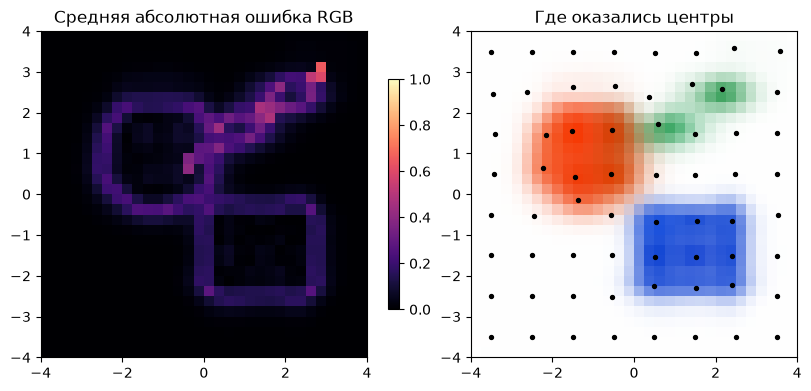

In [7]:
target_array = make_target("shapes", size=32)
target_tensor = torch.tensor(target_array, dtype=torch.float64)
parameters = initialize(target_array, count=64, seed=7, placement="grid", scale=0.55)
optimizer = torch.optim.SGD(list(parameters.values()), lr=4.0)
losses = []

with small_cpu_work():
    for step in range(121):
        optimizer.zero_grad(set_to_none=True)
        image = render_torch(parameters, height=32)
        loss = (image - target_tensor).square().mean()
        losses.append(loss.item())
        if step == 120:
            break
        loss.backward()
        optimizer.step()
        with torch.no_grad():
            parameters["centers"].clamp_(-4, 4)
            parameters["scales"].clamp_(0.2, 3)
            parameters["colors"].clamp_(0, 1)
            parameters["opacity"].clamp_(0, 1)

print("MSE before / after:", losses[0], losses[-1])
assert losses[-1] < losses[0]
result = demo_fit()
assert np.allclose(image.detach().numpy(), result["image"], atol=1e-12)
display(detail_figure(result, language=LANG))

`detach()` в последней проверке отделяет результат от графа, чтобы посмотреть на него как на обычный массив. Это уместно **после** расчёта градиентов или при сохранении картинки. Вставка `detach()` между рендерером и ошибкой оборвала бы обучение.

В коде нет случайного выбора пикселей: на каждом шаге используются все $3072$ канала. Для основной сетки начальные положения тоже детерминированы. Случайное размещение использует `seed=7`, чтобы повторный запуск в том же окружении начинался с тех же пятен. Число seed обозначает начальное состояние генератора, а не качество сцены. NumPy и браузер используют разные генераторы, поэтому одинаковая подпись seed не обещает одинаковый случайный набор между ними; режим сетки даёт общий числовой пример.

Эта модель сравнивает числовые RGB в диапазоне $0..1$ без преобразования цветового пространства. Это то же соглашение, что было в первом блоке. Для физически корректного смешивания цветов и сравнения фотографий выбор цветового пространства потребует отдельного внимания.

## 8. Когда пятен мало, когда они не там и когда они слишком узкие

У $16$ пятен всего $128$ параметров. Ими приходится покрывать большие участки, поэтому тонкая зелёная линия и прямые границы теряются. У $128$ пятен $1024$ параметра, больше возможностей разместить небольшие элементы возле краёв. Это не обещает, что любой запуск с большим числом пятен окажется лучше: положения, ширины, порядок и время обучения тоже влияют.

Для сравнения ниже одинаковы образец, сетка пикселей, начальная ширина $0.55$, размер шага $4$ и $120$ обновлений. Меняется только количество пятен. При этом начальная сетка центров закономерно становится другой. Таблица показывает и исходную ошибку, чтобы подсказка от удачного старта не потерялась.

Есть ещё две отдельные причины плохого результата:

- Если все центры находятся около середины, пустые края могут почти не давать им градиента. Модель сначала должна «дотянуться» до нужных областей.
- Если стартовая ширина слишком мала относительно расстояния между пятнами, между ними остаются пробелы. Слишком широкие пятна, наоборот, мешают друг другу и сначала рисуют размытые цветные облака.

Карта абсолютных различий показывает место ошибки, график MSE — её общий ход. Если MSE падает, но тонкая деталь не появляется, это вполне совместимые наблюдения: большие одноцветные области могли улучшиться сильнее, чем маленькая деталь.

N= 16; parameters= 128; MSE 0.068029 -> 0.022499


N= 64; parameters= 512; MSE 0.032308 -> 0.012089


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.03785843788907092..1.0000000000000004].


N=128; parameters=1024; MSE 0.034382 -> 0.009793


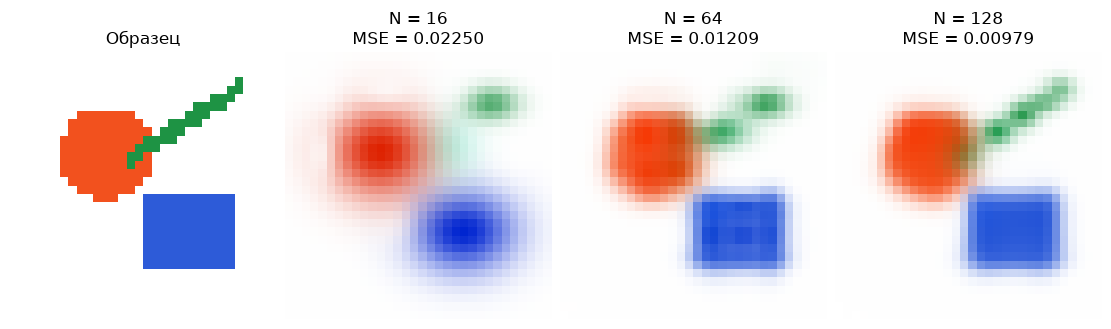

In [8]:
comparison = []
for count in [16, 64, 128]:
    run = demo_fit(count=count)
    comparison.append(run)
    print(f"N={count:3d}; parameters={8*count:4d}; MSE {run['history'][0]:.6f} -> {run['history'][-1]:.6f}")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 4, figsize=(11, 3.2), layout="constrained")
axes[0].imshow(make_target(), origin="lower")
axes[0].set_title("Образец" if LANG == "ru" else "Target")
for ax, run in zip(axes[1:], comparison):
    ax.imshow(run["image"], origin="lower")
    ax.set_title(f"N = {run['settings']['count']}\nMSE = {run['history'][-1]:.5f}")
for ax in axes:
    ax.axis("off")
display(fig)
plt.close(fig)

## 9. Своя картинка и сохранение сцены

Встроенные образцы дают воспроизводимое сравнение. Та же функция обучения принимает произвольный массив RGB размера $(H,W,3)$ с числами от $0$ до $1$. Функция `load_image` открывает локальный файл, уменьшает его до небольшой сетки с сохранением пропорций и добавляет белые поля. Прозрачные участки также смешиваются с белым. При сильном уменьшении исходные мелкие детали исчезнут **до** обучения — модель не сможет восстановить то, чего нет в её образце.

В примере путь остаётся `None`, поэтому используется встроенная картинка. Если в `image_path` находится путь к локальному файлу, обучается он. Файл не отправляется в сеть.

Сохраняется не только PNG. JSON содержит центры, ширины, цвета и непрозрачности в том же формате, который понимает редактор урока 5. В нём останутся угол $0$ и прежний порядок слоёв. Файл позволяет снова нарисовать сцену или доработать её вручную. Сам по себе он не хранит образец, историю ошибки и состояние обучающего цикла, поэтому рядом сохраняются параметры опыта.

Результат записывается в `Path.cwd() / "image-fit-result"`: это папка `image-fit-result` внутри текущей рабочей папки Python. `save_files=False` оставляет результат только в памяти; при `True` появляются `gaussian-scene.json`, `experiment.json`, `target.png` и `result.png`.

In [9]:
image_path = None  # Example: course_root / "my-image.png"
chosen_target = make_target("shapes") if image_path is None else load_image(image_path, size=32)
chosen_result = demo_fit() if image_path is None else fit_image(chosen_target, count=64, steps=120)

# Files are written under Path.cwd() when save_files is True.
save_files = False
if save_files:
    import json
    from PIL import Image
    folder = Path.cwd() / "image-fit-result"
    folder.mkdir(exist_ok=True)
    (folder / "gaussian-scene.json").write_text(chosen_result["scene"], encoding="utf-8")
    experiment = dict(chosen_result["settings"], history=chosen_result["history"],
                      resolution=list(chosen_target.shape[:2]), bounds=[-4, 4, -4, 4])
    (folder / "experiment.json").write_text(json.dumps(experiment, indent=2), encoding="utf-8")
    for filename, array in [("target.png", chosen_target), ("result.png", chosen_result["image"])]:
        rgb = np.rint(np.clip(np.flipud(array), 0, 1) * 255).astype(np.uint8)
        Image.fromarray(rgb).save(folder / filename)

from gaussian_math import load_scene_json, render_layers
layers, background = load_scene_json(chosen_result["scene"])
roundtrip = render_layers(layers, background, size=32)
print("exported layers:", len(layers))
print("largest roundtrip difference:", np.max(np.abs(roundtrip - chosen_result["image"])))
assert np.allclose(roundtrip, chosen_result["image"], atol=1e-12)

exported layers: 64
largest roundtrip difference: 1.4432899320127035e-15


## 10. Что этот проект уже умеет, а чего в нём ещё нет

Получилась программа, которая подбирает числовое описание картинки. На входе — пиксели, на выходе — набор мягких пятен. Можно нарисовать этот набор на более крупной сетке, но новых наблюдений от этого не появится. Гладкий рендер большего размера не доказывает восстановление деталей исходной фотографии.

Это **восстановление изображения гауссианами**, а не реализация метода 2D Gaussian Splatting для восстановления поверхностей в трёхмерной сцене. Здесь нет глубины, камер, проекции и новых ракурсов. Порядок слоёв — порядок списка, а не расстояние до камеры. Эти различия станут существенными в следующем блоке.

Не каждое изображение удастся точно описать фиксированным числом таких пятен. Даже когда хорошее описание существует, обычный градиентный спуск может его не найти из данного старта. Маленькая MSE означает хорошее совпадение выбранных чисел на выбранной сетке; она не гарантирует ни единственности параметров, ни идеального визуального впечатления.

Следующая ступень — добавить пространство и камеру. Пятна уже не будут храниться непосредственно на плоскости картинки: их положение и форма пройдут через проекцию. Но обратный путь останется узнаваемым: изображение → ошибка → градиенты → параметры сцены.

## 11. Три небольших исследования

**Количество.** Один и тот же образец, $16$ и $128$ пятен, одинаковые $120$ шагов. В таблице выше у большего набора ошибка ниже. На клетчатом образце преимущество может проявиться иначе: важны размер клетки и расположение центров. По карте различий видно, какие участки выиграли.

**Стартовая ширина.** При $64$ пятнах сравним $0.2$, $0.55$ и $1.5$. До обучения стоит отметить пробелы или сильные перекрытия. После — сопоставить скорость снижения MSE и форму оставшейся ошибки.

**Дольше или иначе.** Для неудачного старта можно сравнить ещё $120$ шагов с новым начальным размещением. Уменьшение ошибки при продолжении не означает, что найден лучший возможный набор. Перезапуск иногда помогает, а иногда отбрасывает полезный результат.

<details>
<summary>Разбор: почему больше пятен не означает вдвое лучше</summary>

Дополнительные пятна дают параметры, но ещё должны оказаться в полезных местах. Они могут перекрывать друг друга, рисовать одно и то же или оставаться почти невидимыми. В данной программе новых пятен в проблемных местах никто не добавляет, бесполезные не удаляет. Такие операции изменяют сам набор элементов и будут отдельно разобраны в блоке о полноценном 3DGS.

</details>

<details>
<summary>Разбор: почти нулевая непрозрачность и движение центра</summary>

Положение меняет $G$, затем $\alpha=oG$. Если $o$ почти ноль, изменение веса почти не меняет локальную непрозрачность: множитель $o$ гасит этот путь градиента. Сам параметр непрозрачности ещё может получить градиент через множитель $G$, если пятно находится возле полезной области. Поэтому исчезнувшее пятно не обязательно навсегда потеряно, но одновременно невидимое и далёкое часто учится медленно.

</details>

<details>
<summary>Разбор: что сравнивать между двумя опытами</summary>

Нужны одинаковые образец, разрешение, функция ошибки и шкала цветов. Одинаковое число шагов не означает одинаковое время: большее число пятен требует больше вычислений. Полезно сохранять оба значения, начальную и финальную MSE, настройки и сами картинки. Один удачный seed не доказывает устойчивость метода; несколько повторений показывают, насколько результат зависит от старта.

</details>